In [4]:
import kagglehub
import os
import zipfile
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [5]:
pasta_kaggle = kagglehub.dataset_download(
    "uciml/human-activity-recognition-with-smartphones"
)

print(os.listdir(pasta_kaggle))

Using Colab cache for faster access to the 'human-activity-recognition-with-smartphones' dataset.
['train.csv', 'test.csv']


In [6]:
df_train = pd.read_csv(
    os.path.join(pasta_kaggle, "train.csv")
)

df_test = pd.read_csv(
    os.path.join(pasta_kaggle, "test.csv")
)

print("Treinamento:", df_train.shape)
print("Teste:", df_test.shape)
print("Colunas:", df_train.columns.tolist()[-10:])

df_train.head()

Treinamento: (7352, 563)
Teste: (2947, 563)
Colunas: ['fBodyBodyGyroJerkMag-kurtosis()', 'angle(tBodyAccMean,gravity)', 'angle(tBodyAccJerkMean),gravityMean)', 'angle(tBodyGyroMean,gravityMean)', 'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)', 'angle(Y,gravityMean)', 'angle(Z,gravityMean)', 'subject', 'Activity']


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


In [7]:
pd.DataFrame({
    "Treinamento": df_train["Activity"].value_counts(),
    "Teste": df_test["Activity"].value_counts()
}).fillna(0).astype(int)

,Treinamento,Teste
Activity,,
LAYING,1407,537
SITTING,1286,491
STANDING,1374,532
WALKING,1226,496
WALKING_DOWNSTAIRS,986,420
WALKING_UPSTAIRS,1073,471


In [8]:
print("Participantes no treinamento:")
print(sorted(df_train["subject"].unique()))

print("\nParticipantes no teste:")
print(sorted(df_test["subject"].unique()))

print("\nParticipantes em ambos:")
print(
    set(df_train["subject"]) &
    set(df_test["subject"])
)

Participantes no treinamento:
[np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]

Participantes no teste:
[np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]

Participantes em ambos:
set()


In [10]:
!wget -q https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip -O uci_har.zip
!unzip -qo uci_har.zip -d uci_har
!unzip -qo "uci_har/UCI HAR Dataset.zip" -d uci_har

pasta_dataset = "uci_har/UCI HAR Dataset"

In [11]:
sensores = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

def carregar_sinais(conjunto):
    sinais = [
        np.loadtxt(
            os.path.join(
                pasta_dataset,
                conjunto,
                "Inertial Signals",
                f"{sensor}_{conjunto}.txt"
            )
        )
        for sensor in sensores
    ]

    return np.stack(sinais, axis=2).astype("float32")

X_train = carregar_sinais("train")
X_test = carregar_sinais("test")

y_train = np.loadtxt(
    os.path.join(pasta_dataset, "train", "y_train.txt"),
    dtype=int
) - 1

y_test = np.loadtxt(
    os.path.join(pasta_dataset, "test", "y_test.txt"),
    dtype=int
) - 1

print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

Treinamento: (7352, 128, 9)
Teste: (2947, 128, 9)


In [12]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Treinamento:", X_train_final.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treinamento: (5881, 128, 9)
Validação: (1471, 128, 9)
Teste: (2947, 128, 9)


In [13]:
tf.keras.utils.set_random_seed(42)

modelo_gru = Sequential([
    Input(shape=(128, 9)),
    GRU(64, return_sequences=True),
    Dropout(0.3),
    GRU(32),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(6, activation="softmax")
])

modelo_gru.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_gru.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 128, 64)        │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,062 (97.90 KB)

 Trainable params: 25,062 (97.90 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

inicio = time.time()

historico = modelo_gru.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

tempo_treinamento = time.time() - inicio

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.4268 - loss: 1.3631 - val_accuracy: 0.5201 - val_loss: 1.0742
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5321 - loss: 1.0558 - val_accuracy: 0.5880 - val_loss: 0.9486
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6212 - loss: 0.8844 - val_accuracy: 0.7288 - val_loss: 0.6594
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7392 - loss: 0.6065 - val_accuracy: 0.7838 - val_loss: 0.4757
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8101 - loss: 0.4661 - val_accuracy: 0.8606 - val_loss: 0.3342
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8796 - loss: 0.3330 - val_accuracy: 0.9327 - val_loss: 0.2268
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9163 - loss: 0.2387 - val_accuracy: 0.9273 - val_loss: 0.1785
Epoch 8/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9294 - loss: 0.1958 - val_accuracy: 0.

In [15]:
perda_teste, acuracia_teste = modelo_gru.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Acurácia no teste: {acuracia_teste:.2%}")
print(f"Perda no teste: {perda_teste:.4f}")

Acurácia no teste: 90.13%
Perda no teste: 0.3174


In [16]:
y_pred_prob = modelo_gru.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

precisao = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

print(f"Precisão Macro: {precisao:.4f}")
print(f"Recall Macro: {recall:.4f}")
print(f"F1-score Macro: {f1:.4f}")

Precisão Macro: 0.9022
Recall Macro: 0.9037
F1-score Macro: 0.9026


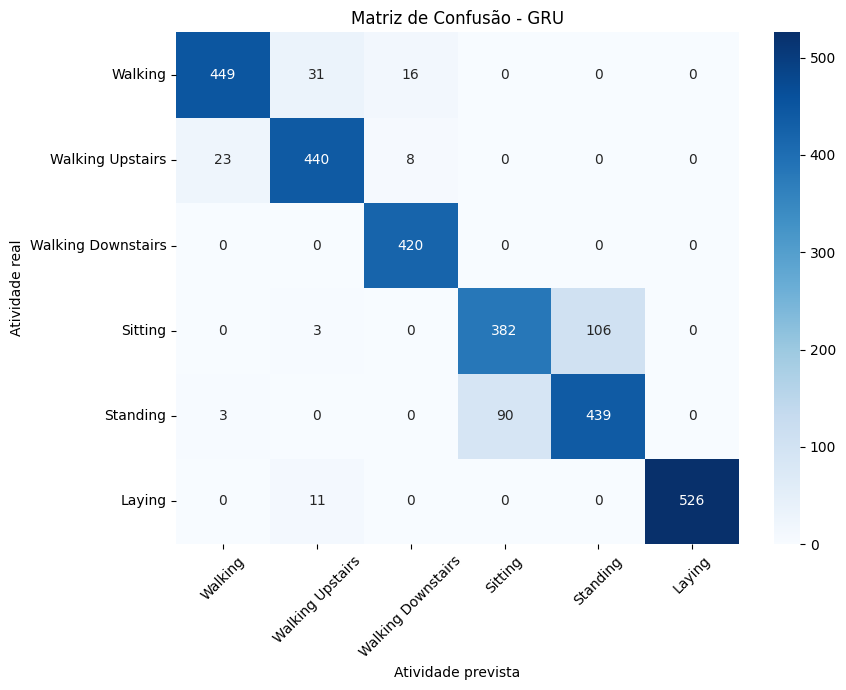

In [17]:
atividades = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=atividades,
    yticklabels=atividades
)

plt.title("Matriz de Confusão - GRU")
plt.xlabel("Atividade prevista")
plt.ylabel("Atividade real")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

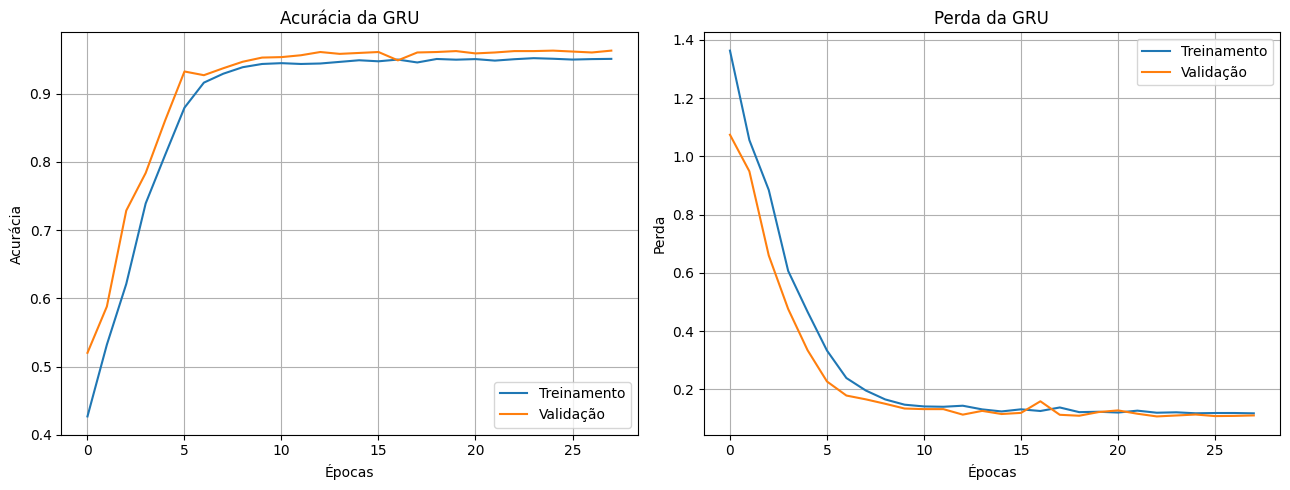

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(historico.history["accuracy"], label="Treinamento")
axes[0].plot(historico.history["val_accuracy"], label="Validação")
axes[0].set_title("Acurácia da GRU")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Acurácia")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(historico.history["loss"], label="Treinamento")
axes[1].plot(historico.history["val_loss"], label="Validação")
axes[1].set_title("Perda da GRU")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Perda")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [19]:
modelo_gru.save("modelo_gru_uci_har.keras")

In [22]:
pip install -q shap

In [24]:
import shap

amostra = X_test[0]
referencia = X_train_final.mean(axis=0)

classe_prevista = np.argmax(
    modelo_gru.predict(amostra[np.newaxis, :, :], verbose=0)
)

def prever_shap(mascaras):
    entradas = np.repeat(
        referencia[np.newaxis, :, :],
        len(mascaras),
        axis=0
    )

    for i, mascara in enumerate(mascaras):
        canais = np.where(mascara > 0.5)[0]
        entradas[i][:, canais] = amostra[:, canais]

    probabilidades = modelo_gru.predict(
        entradas,
        verbose=0
    )

    return probabilidades[:, classe_prevista]

explainer = shap.KernelExplainer(
    prever_shap,
    np.zeros((1, 9))
)

valores_shap = explainer.shap_values(
    np.ones((1, 9)),
    nsamples=128
)

print("Classe prevista:", atividades[classe_prevista])
print("Formato SHAP:", np.asarray(valores_shap).shape)

  0%|          | 0/1 [00:00<?, ?it/s]

Classe prevista: Standing
Formato SHAP: (1, 9)


In [25]:
np.random.seed(42)

indices = np.random.choice(
    len(X_train_final),
    size=30,
    replace=False
)

background = X_train_final[indices]
amostras_shap = X_test[:5]

explainer_grad = shap.GradientExplainer(
    modelo_gru,
    background
)

valores_shap_grad = explainer_grad.shap_values(
    amostras_shap,
    nsamples=100
)

print("Formato Gradient SHAP:", np.asarray(valores_shap_grad).shape)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_7
Received: inputs=['Tensor(shape=(5, 128, 9))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_7
Received: inputs=['Tensor(shape=(50, 128, 9))']
  warnings.warn(msg)


Formato Gradient SHAP: (5, 128, 9, 6)


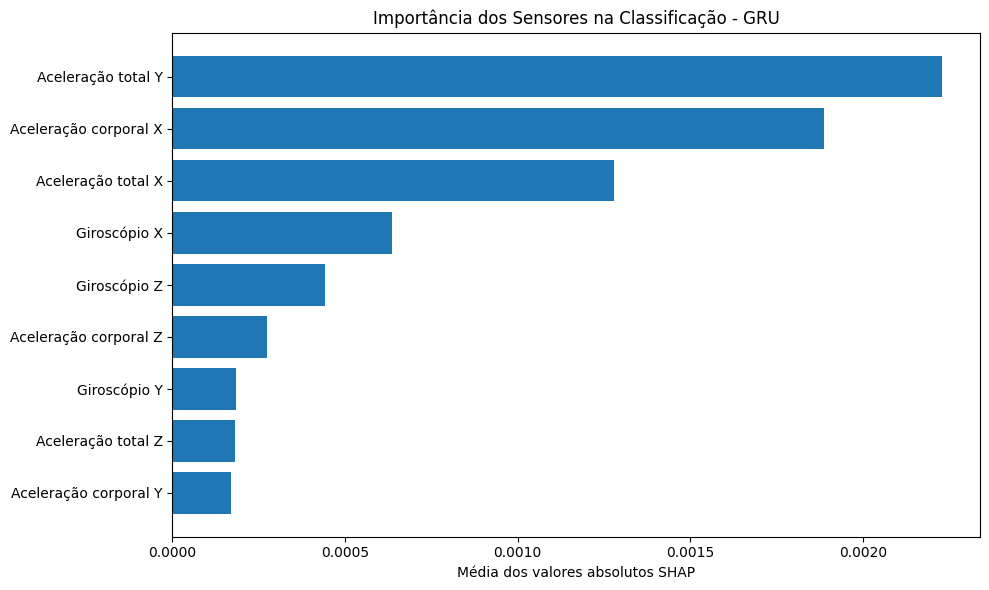

In [26]:
valores = np.asarray(valores_shap_grad)

classes_previstas = np.argmax(
    modelo_gru.predict(amostras_shap, verbose=0),
    axis=1
)

contribuicoes = np.stack([
    valores[i, :, :, classes_previstas[i]]
    for i in range(len(amostras_shap))
])

importancia = np.mean(np.abs(contribuicoes), axis=(0, 1))

nomes_sensores = [
    "Aceleração corporal X",
    "Aceleração corporal Y",
    "Aceleração corporal Z",
    "Giroscópio X",
    "Giroscópio Y",
    "Giroscópio Z",
    "Aceleração total X",
    "Aceleração total Y",
    "Aceleração total Z"
]

ordem = np.argsort(importancia)

plt.figure(figsize=(10, 6))
plt.barh(
    np.array(nomes_sensores)[ordem],
    importancia[ordem]
)

plt.xlabel("Média dos valores absolutos SHAP")
plt.title("Importância dos Sensores na Classificação - GRU")
plt.tight_layout()
plt.show()

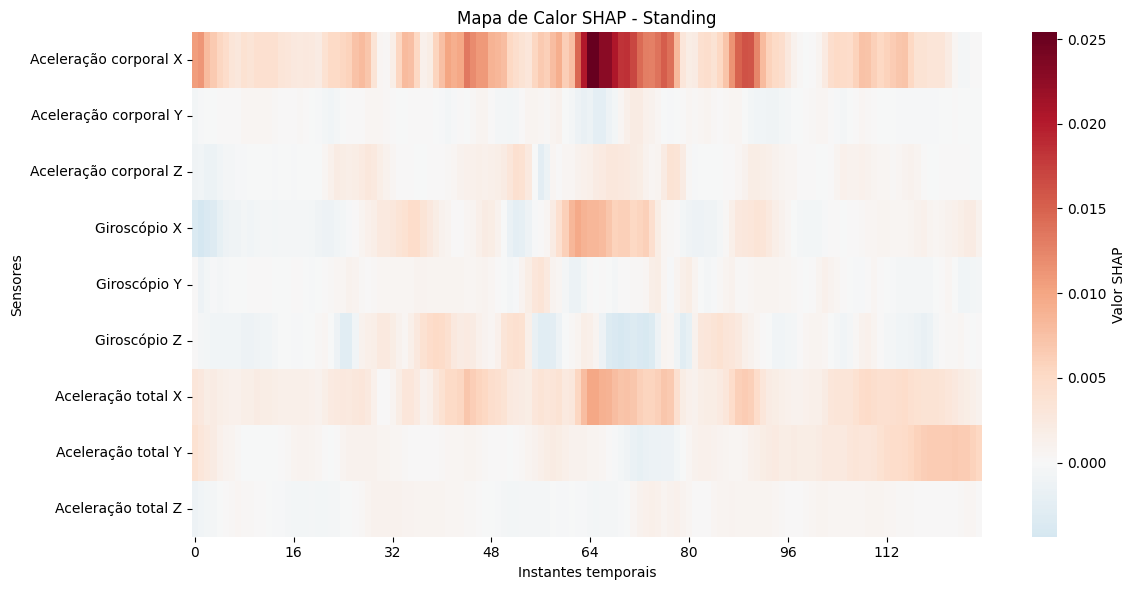

In [27]:
indice = 0

classe = classes_previstas[indice]
mapa_shap = valores[indice, :, :, classe]

plt.figure(figsize=(12, 6))

sns.heatmap(
    mapa_shap.T,
    cmap="RdBu_r",
    center=0,
    xticklabels=16,
    yticklabels=nomes_sensores,
    cbar_kws={"label": "Valor SHAP"}
)

plt.title(f"Mapa de Calor SHAP - {atividades[classe]}")
plt.xlabel("Instantes temporais")
plt.ylabel("Sensores")
plt.tight_layout()
plt.show()